# Allele frequencies and random sampling

Why can an allele frequency change even when neither allele has a selective advantage?

Fall 2024.


# Allele frequencies and random sampling
Predict: can an allele increase without an advantage? First count the copies in 4 AA, 10 AB, 6 BB. Then predict which population size should fluctuate more. These are synthetic neutral models, not real genetic data.

A frequency: 0.45
Genotype probabilities: [0.09 0.42 0.49]


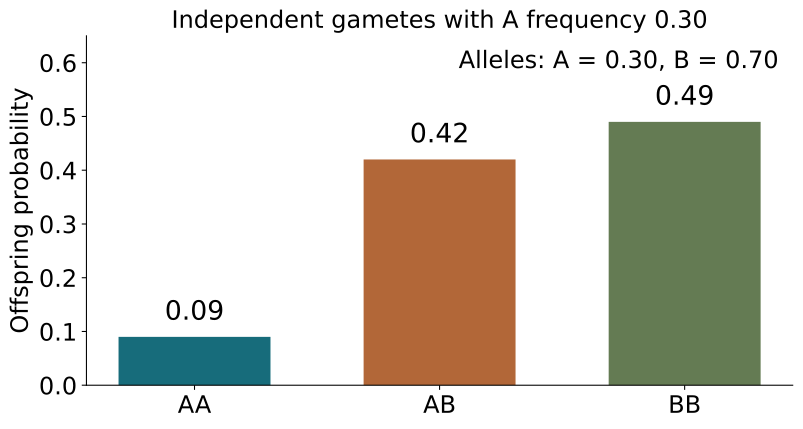

In [1]:
from demo import run, genotype_frequencies, allele_frequency, drift
import numpy as np
from IPython.display import SVG, display
results = run()
print('A frequency:', allele_frequency(4,10,6))
print('Genotype probabilities:', genotype_frequencies(.3))
display(SVG(filename='genotype-probabilities.svg'))

Interpret the probabilities before the trajectories. Expected genotype counts can differ from one realized census. In the next plot, the dashed line is the theoretical expected allele frequency; it is not a fit or the mean of the displayed eight paths.

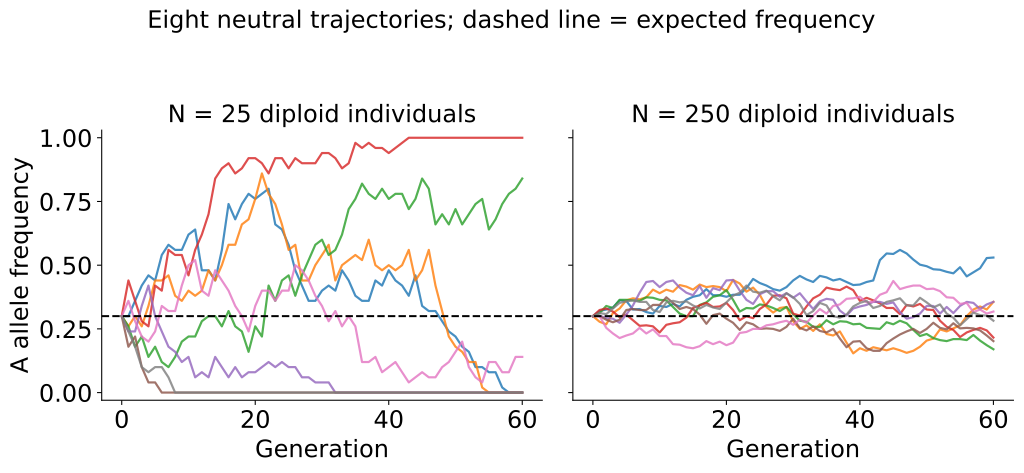

{'replicates': 100000, 'mean_copies': 15.01497, 'variance_copies': 10.5046658991, 'expected_mean': 15.0, 'expected_variance': 10.5}


In [2]:
display(SVG(filename='neutral-drift.svg'))
print(results['one_generation_ensemble'])

Modify: keep p0 =0.30 but change N to 100, choosing 60 starting A copies. Use a different seed for another realization. Inspect bounds and the attainable copy grid before interpreting the outcome.

In [3]:
generation, paths = drift(initial_copies=60, population=100, seed=101)
assert np.all((paths >= 0) & (paths <= 1))
assert np.allclose(paths*200, np.round(paths*200))
print('Eight final frequencies:', paths[-1])
print('One-step variance at initial p:', .3*.7/200)

Eight final frequencies: [0.58  0.26  0.    0.685 0.38  0.29  0.    0.5  ]
One-step variance at initial p: 0.00105


Check a limit: predict the result if A is absent, then run. Explain which omitted mechanism would be needed for A to reappear. Try several independent seeds for exploration; repeating the same seed is a reproducibility check.

In [4]:
_, absent = drift(initial_copies=0, population=100)
assert np.all(absent == 0)
print('Absent allele remains absent:', np.all(absent == 0))

Absent allele remains absent: True
